# Triggering Conditions and Scenario-Based Evaluation

**Module 04 · SOTIF (ISO 21448)** · Notebook 2 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [01 · SOTIF fundamentals](01_sotif_fundamentals.ipynb) | ISO 21448:2022, ISO 34502:2022, ISO 34503:2023 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Build a triggering-condition catalogue structured by the PEGASUS **6-layer model** and keep out-of-scope causes apart
- Link triggering conditions to **functional insufficiencies** (specification vs performance)
- Use the scenario abstraction levels **functional → logical → concrete** and distinguish a scenario from the **ODD** (ISO 34503:2023)
- Describe the **ISO 34502:2022** scenario-based safety evaluation framework and the role of **ASAM OpenSCENARIO / OpenODD**
- Generate a scenario space, measure **n-wise coverage** and build a **pairwise test set** in Python
- Explain what coverage of a discretised space does — and does not — say about residual risk

In [1]:
# Setup
from itertools import combinations, product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

rng = np.random.default_rng(42)
OI = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442',
      'blue': '#0072B2', 'vermillion': '#D55E00', 'purple': '#CC79A7', 'grey': '#999999', 'black': '#000000'}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print("Setup complete.")

Setup complete.


## 1. Recap: where triggering conditions sit

ISO 21448:2022 addresses hazards caused by **functional insufficiencies** — insufficiencies of specification and
performance insufficiencies — of a function that is working as designed. A **triggering condition** is a specific
condition of a scenario that activates such an insufficiency:

```
Triggering condition → activates functional insufficiency → output insufficiency
   → propagates to hazardous behaviour → in a scenario without sufficient controllability → harm
```

> "The system is not broken — it just cannot handle this scenario."

Unlike ISO 26262, which handles random hardware faults and systematic hardware/software faults, SOTIF analyses the
**scenarios** in which a fault-free function is insufficient. This notebook is about building those scenarios
systematically. Areas 1–4 were introduced in [Notebook 01](01_sotif_fundamentals.ipynb): Area 1 known/not hazardous,
Area 2 known/hazardous, **Area 3 unknown/hazardous**, Area 4 unknown/not hazardous.

## 2. Scenario vocabulary

**Operational design domain (ODD)** — the operating conditions under which a function is designed to work
(SAE J3016:2021). **ISO 34503:2023** specifies a hierarchical ODD taxonomy with three top-level attribute groups:

| ISO 34503 top-level attribute | Contents (examples) |
|---|---|
| **Scenery** | Non-movable elements: road type and geometry, lane markings, junctions, signs, bridges, tunnels, roadside structures |
| **Environmental conditions** | Weather (rain, snow, wind, temperature), particulates (fog, dust), illumination (day, night, low sun), connectivity |
| **Dynamic elements** | Movable objects and actors: other traffic participants, their density and behaviour, and the subject vehicle itself (e.g. speed) |

ISO 34503 is aimed mainly at Level 3 and Level 4 automated driving systems. **ASAM OpenODD 1.0.0** (released April 2025)
provides machine-readable ODD formats (YAML, tabular, OpenSCENARIO DSL) so that an ODD can be checked against
scenarios and data automatically.

A **scenario** is a temporal sequence of scenes with actions and events of the participants. An ODD says *where and
when* the function may operate; scenarios are *what happens* there. A scenario can lie inside the ODD, outside it, or
cross its boundary (an **ODD exit**, which the function must detect and handle).

**Abstraction levels** (Menzel, Bagschik & Maurer, 2018):

| Level | Description | Example |
|---|---|---|
| **Functional** | Linguistic description for experts | "On an urban road, a pedestrian crosses in front of the vehicle, possibly hidden by a parked car" |
| **Logical** | Parameters with **ranges** (and possibly distributions) | ego speed 30–50 km/h; illumination ∈ {day, dusk, night lit}; occlusion ∈ {none, parked car} |
| **Concrete** | One fixed **value** per parameter — executable in a simulator or on a test track | ego 40 km/h, dusk, light rain, child, running, occluded |

One logical scenario defines a **scenario space**; concrete scenarios are samples from it.

## 3. Structuring triggering conditions: the 6-layer model

The **6-layer model** from the German PEGASUS project — formalised for urban traffic by Scholtes et al. (2021) — is
a widely used structure for describing the environment of a scenario. Using it for a triggering-condition catalogue
makes gaps visible.

| Layer | Content | Triggering-condition examples (camera/LiDAR perception) |
|---|---|---|
| L1 Road network & traffic guidance | Road geometry, markings, signs | Faded or contradictory markings, non-standard signs, sharp curves |
| L2 Roadside structures | Buildings, barriers, vegetation | Parked-vehicle rows, hedges hiding pedestrians, reflective façades |
| L3 Temporary modifications of L1/L2 | Construction zones, temporary markings | Yellow temporary lines over white ones, shifted lanes |
| L4 Dynamic objects | Road users, their types and behaviour | Child running out, wheelchair user, animal, wrong-way driver |
| L5 Environmental conditions | Weather, lighting, road surface | Heavy rain, fog, low sun, tunnel exit, wet reflective road |
| L6 Digital information | V2X, maps, digital signals | Outdated HD map after re-routing, missing V2X message |

**Mapping to ISO 34503 (approximate):** scenery ≈ L1–L3, environmental conditions ≈ L5 (connectivity ≈ L6),
dynamic elements ≈ L4.

Two further groups matter for SOTIF but sit outside the 6 layers: **external disturbances of sensors** (dirt, spray,
ice on the sensor cover) and **driver behaviour, including reasonably foreseeable misuse**.

Things that look like triggering conditions but are **not**:

- *Hardware degradation, EMI, memory overflow, data corruption, timeouts* → E/E faults → **ISO 26262**
- *Adversarial patterns, spoofing* → attacks → **ISO/SAE 21434**
- *"Out-of-distribution input", "domain shift", "rare class"* → properties of the **system's** training-data coverage,
  i.e. **functional (performance) insufficiencies**, not conditions of the scenario.

In [2]:
# Triggering-condition catalogue, structured by the 6-layer model (+ sensor exposure and driver behaviour)
triggering_conditions = {
    'L1 Road network': ['Faded lane markings', 'Contradictory markings', 'Non-standard traffic sign', 'Sharp curve'],
    'L2 Roadside structures': ['Row of parked vehicles', 'Hedge at the kerb', 'Reflective glass facade'],
    'L3 Temporary modifications': ['Construction zone with shifted lanes', 'Temporary yellow markings', 'Mobile traffic light'],
    'L4 Dynamic objects': ['Child running out', 'Wheelchair user', 'Person carrying a large object',
                           'Animal on road', 'Cyclist emerging from side street', 'Wrong-way driver'],
    'L5 Environment': ['Heavy rain', 'Dense fog', 'Low sun in field of view', 'Tunnel exit (glare)',
                       'Night, unlit road', 'Wet road with reflections', 'Snowfall'],
    'L6 Digital information': ['Outdated HD map', 'Missing V2X message'],
    'Sensor exposure': ['Dirt or mud on lens', 'Water spray from truck', 'Ice on sensor cover',
                        'Retro-reflector saturating LiDAR'],
    'Driver behaviour / misuse': ['Hands off wheel for long periods (L2)', 'Driver asleep or reading',
                                  'Activation outside the ODD'],
}

# Causes that belong to other standards — kept separate on purpose
out_of_scope = {
    'ISO 26262 (E/E faults)': ['Hardware degradation', 'EMI', 'Memory overflow', 'Data corruption', 'Timeout'],
    'ISO/SAE 21434 (security)': ['Adversarial patch', 'LiDAR spoofing', 'GNSS spoofing'],
}

tc_df = pd.DataFrame([{'TC-ID': f'TC-{i+1:02d}', 'Group': g, 'Triggering condition': c}
                      for i, (g, c) in enumerate((g, c) for g, cs in triggering_conditions.items() for c in cs)])
print(f"Triggering conditions in catalogue: {len(tc_df)}")
display(tc_df['Group'].value_counts().rename('count').to_frame())
print("Kept out of the SOTIF catalogue:",
      "; ".join(f"{k}: {len(v)} items" for k, v in out_of_scope.items()))

Triggering conditions in catalogue: 32


,count
Group,
L5 Environment,7
L4 Dynamic objects,6
L1 Road network,4
Sensor exposure,4
L2 Roadside structures,3
L3 Temporary modifications,3
Driver behaviour / misuse,3
L6 Digital information,2


Kept out of the SOTIF catalogue: ISO 26262 (E/E faults): 5 items; ISO/SAE 21434 (security): 3 items


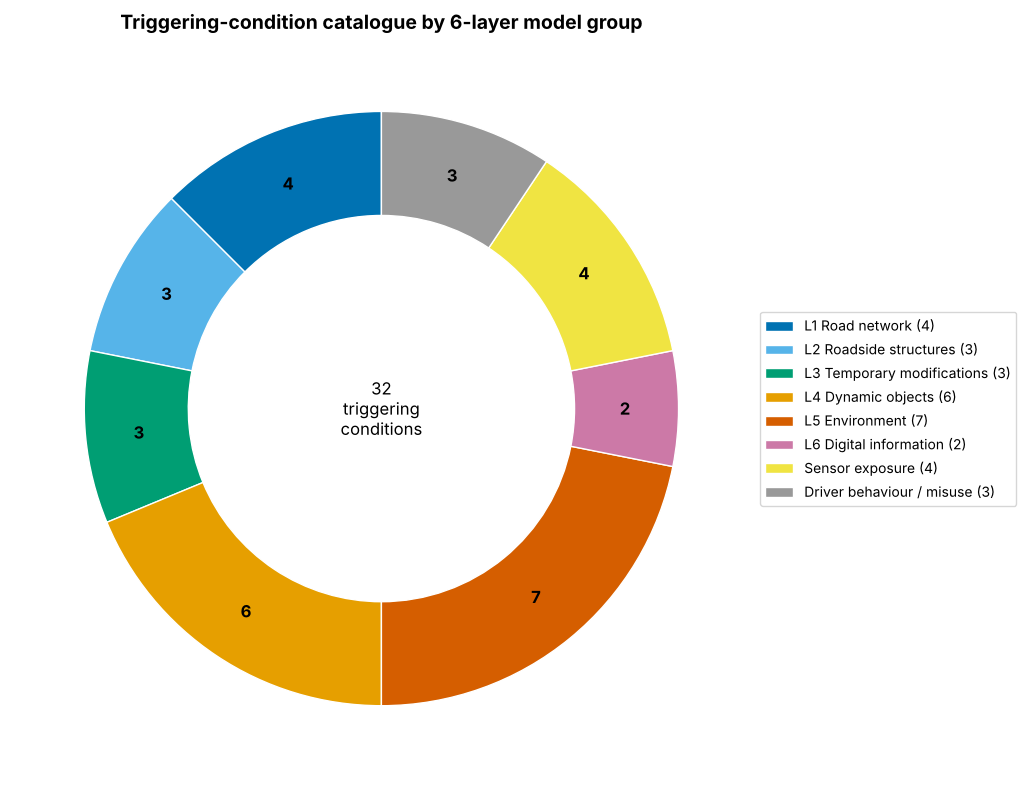

In [3]:
def visualize_triggering_conditions():
    """Nested donut: groups (inner ring) and number of triggering conditions per group (outer ring)."""
    palette = [OI['blue'], OI['sky'], OI['green'], OI['orange'], OI['vermillion'], OI['purple'],
               OI['yellow'], OI['grey']]
    groups = list(triggering_conditions)
    sizes = [len(triggering_conditions[g]) for g in groups]
    fig, ax = plt.subplots(figsize=(11, 8))
    wedges, _ = ax.pie(sizes, radius=1.0, colors=palette, startangle=90,
                       wedgeprops=dict(width=0.35, edgecolor='white'))
    for w, n in zip(wedges, sizes):
        ang = np.deg2rad((w.theta2 + w.theta1) / 2)
        ax.text(0.82 * np.cos(ang), 0.82 * np.sin(ang), str(n), ha='center', va='center',
                fontsize=12, fontweight='bold')
    ax.legend(wedges, [f'{g} ({n})' for g, n in zip(groups, sizes)], loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=10)
    ax.text(0, 0, f'{sum(sizes)}\ntriggering\nconditions', ha='center', va='center', fontsize=12)
    ax.set_title('Triggering-condition catalogue by 6-layer model group', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_triggering_conditions()

## 4. Functional insufficiencies

ISO 21448:2022 knows two types: **insufficiency of specification** and **performance insufficiency**. The table
below links each insufficiency to the triggering conditions that activate it and to the resulting output
insufficiency. Training-data coverage problems ("OOD input", "rare class") appear here — as performance
insufficiencies of the algorithm.

Note on FI-05: "the ODD excludes construction zones" is a design decision, not an insufficiency. The insufficiency is
that the **specification does not define behaviour when approaching** an excluded construction zone (ODD exit).

In [4]:
functional_insufficiencies = pd.DataFrame({
    'FI-ID': ['FI-01', 'FI-02', 'FI-03', 'FI-04', 'FI-05', 'FI-06', 'FI-07', 'FI-08'],
    'ISO 21448 type': ['Performance', 'Performance', 'Performance', 'Performance', 'Specification',
                       'Performance', 'Performance', 'Specification'],
    'Element': ['Camera', 'LiDAR', 'Detector (training-data coverage)', 'Tracker', 'Function specification',
                'Sensor fusion', 'Detector (training-data coverage)', 'Function specification'],
    'Description': [
        'Limited dynamic range of the camera',
        'Reduced range and spurious returns in heavy rain/spray',
        'Low recall for under-represented road-user types',
        'Tracks lost after long occlusion',
        'No specified behaviour on approach to a construction zone (ODD exit)',
        'Misassociation when objects are close together',
        'Low recall for unusual poses (crouching, carrying objects)',
        'No requirement for pedestrians emerging at short time-to-collision',
    ],
    'Activated by': ['Low sun in field of view; Tunnel exit (glare)', 'Heavy rain; Water spray from truck',
                     'Wheelchair user; Animal on road', 'Row of parked vehicles', 'Construction zone with shifted lanes',
                     'Cyclist emerging from side street', 'Person carrying a large object', 'Child running out'],
    'Output insufficiency': ['Missed detection', 'Reduced detection range; false positives',
                             'Missed or misclassified object', 'Late re-detection', 'Undefined vehicle behaviour',
                             'Wrong object position/velocity', 'Missed detection', 'Braking starts too late'],
})
display(functional_insufficiencies)

# Consistency check: every activating TC must exist in the catalogue
all_tcs = set(tc_df['Triggering condition'])
missing = {t.strip() for cell in functional_insufficiencies['Activated by'] for t in cell.split(';')} - all_tcs
types = functional_insufficiencies['ISO 21448 type'].value_counts()
print(f"Text summary: {len(functional_insufficiencies)} functional insufficiencies "
      f"({', '.join(f'{k}: {v}' for k, v in types.items())}); "
      f"triggering conditions referenced but missing from the catalogue: {sorted(missing) if missing else 'none'}")

,FI-ID,ISO 21448 type,Element,Description,Activated by,Output insufficiency
0,FI-01,Performance,Camera,Limited dynamic range of the camera,Low sun in field of view; Tunnel exit (glare),Missed detection
1,FI-02,Performance,LiDAR,Reduced range and spurious returns in heavy ra...,Heavy rain; Water spray from truck,Reduced detection range; false positives
2,FI-03,Performance,Detector (training-data coverage),Low recall for under-represented road-user types,Wheelchair user; Animal on road,Missed or misclassified object
3,FI-04,Performance,Tracker,Tracks lost after long occlusion,Row of parked vehicles,Late re-detection
4,FI-05,Specification,Function specification,No specified behaviour on approach to a constr...,Construction zone with shifted lanes,Undefined vehicle behaviour
5,FI-06,Performance,Sensor fusion,Misassociation when objects are close together,Cyclist emerging from side street,Wrong object position/velocity
6,FI-07,Performance,Detector (training-data coverage),"Low recall for unusual poses (crouching, carry...",Person carrying a large object,Missed detection
7,FI-08,Specification,Function specification,No requirement for pedestrians emerging at sho...,Child running out,Braking starts too late


Text summary: 8 functional insufficiencies (Performance: 6, Specification: 2); triggering conditions referenced but missing from the catalogue: none


## 5. ISO 34502:2022 — scenario-based safety evaluation framework

**ISO 34502:2022** *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation
framework* gives guidance for building and using a scenario space during ADS development. Its scope is ADS on
**limited-access highways**; misuse, HMI and cybersecurity are excluded. The framework is aligned with ISO 21448 and
adds a scenario-based process for identifying risk factors. In outline:

1. **Identify risk factors** from the ODD and the system (perception, planning, vehicle motion).
2. **Structure critical scenarios** systematically, rooted in physical principles of how disturbances arise; the
   framework, which builds on the Japanese JAMA/SAKURA approach, distinguishes disturbances related to traffic,
   to perception and to vehicle motion *(terms paraphrased; check the standard's own wording)*.
3. **Parameterise** them as logical scenarios and derive concrete test scenarios.
4. **Evaluate** by simulation, proving ground and public-road tests against defined criteria; an informative annex
   discusses risk evaluation based on a positive risk balance.

**ISO 34503:2023** (ODD taxonomy, above) and **ISO 34504** (scenario categorisation) complete the ISO 345xx family.

## 6. Hands-on: scenario space and n-wise coverage

We build the logical scenario *"pedestrian crossing in front of an urban AEB vehicle"* with seven discretised
parameters. A full-factorial design quickly becomes large; **combinatorial (n-wise) testing** asks instead that every
combination of values of any *n* parameters appears in at least one test. Many failures are caused by interactions
of few parameters, so pairwise (n = 2) or 3-wise test sets find much with few tests (see the NIST combinatorial-testing resources in the references).

The coverage function below reproduces `avsafety.coverage.nwise_coverage` (see repo `avsafety/`) and adds an optional
`valid` filter, so that physically impossible combinations (rain on a dry road) are not counted as gaps.

In [5]:
# Logical scenario: discretised parameter domains
domains = {
    'ego_speed_kmh': [30, 40, 50],
    'illumination': ['day', 'dusk', 'night_lit'],
    'precipitation': ['none', 'light_rain', 'heavy_rain'],
    'road_surface': ['dry', 'wet'],
    'pedestrian': ['adult', 'child', 'wheelchair'],
    'occlusion': ['none', 'parked_car'],
    'ped_motion': ['walk', 'run'],
}

def is_valid(sc):
    """Physical constraint: precipitation implies a wet road."""
    return not (sc['precipitation'] != 'none' and sc['road_surface'] == 'dry')

def full_factorial(domains):
    keys = sorted(domains)
    return [dict(zip(keys, vals)) for vals in product(*(domains[k] for k in keys))]

def nwise_coverage(domains, scenarios, n=2, valid=None):
    """Fraction of n-way value combinations exercised by `scenarios`.
    With valid=None this equals avsafety.coverage.nwise_coverage; with a `valid` predicate only combinations
    that occur in at least one valid full scenario are required."""
    params = sorted(domains)
    if valid is None:
        required = {tuple(zip(c, v)) for c in combinations(params, n) for v in product(*(domains[p] for p in c))}
    else:
        required = {tuple((p, sc[p]) for p in c) for sc in full_factorial(domains) if valid(sc)
                    for c in combinations(params, n)}
    seen = {tuple((p, sc[p]) for p in c) for sc in scenarios for c in combinations(params, n)}
    covered = required & seen
    return {'coverage': len(covered) / len(required), 'covered': len(covered), 'total': len(required),
            'missing': sorted(required - seen)}

universe = [sc for sc in full_factorial(domains) if is_valid(sc)]
print(f"Full factorial: {len(full_factorial(domains))} concrete scenarios, of which {len(universe)} are physically valid")
for n in (1, 2, 3):
    print(f"  required {n}-wise value combinations (valid only): {nwise_coverage(domains, [], n, is_valid)['total']}")

Full factorial: 648 concrete scenarios, of which 432 are physically valid
  required 1-wise value combinations (valid only): 18
  required 2-wise value combinations (valid only): 136
  required 3-wise value combinations (valid only): 558


### 6.1 A pairwise test set

A simple greedy algorithm (in the spirit of AETG) repeatedly picks the valid concrete scenario that covers the most
not-yet-covered pairs. Compare its size with random sampling.

Greedy pairwise suite: 15 tests → 2-wise coverage 100%, 3-wise coverage 65% (out of 432 valid scenarios)


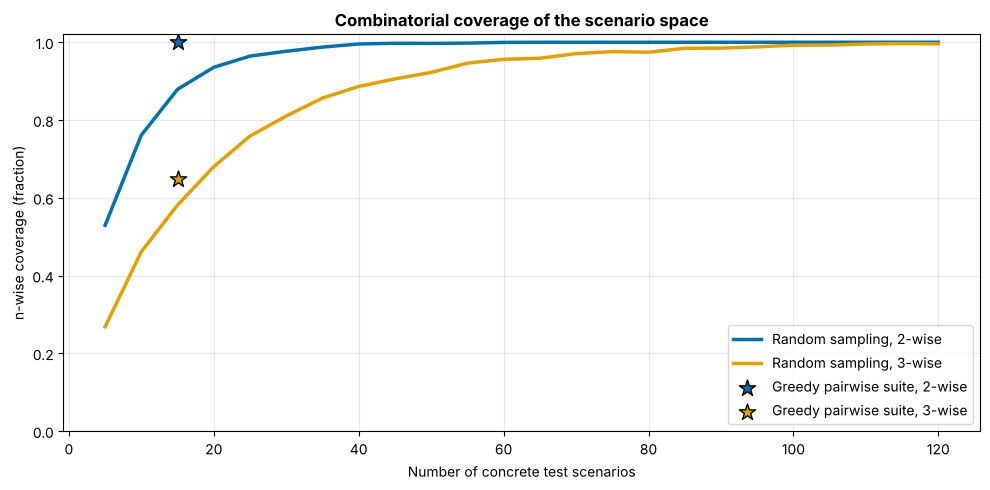

Text summary: 15 greedy tests give full pairwise coverage; random sampling needs about 60 tests on average.


In [6]:
def pairs_of(sc, params):
    return {tuple((p, sc[p]) for p in c) for c in combinations(params, 2)}

def greedy_pairwise(universe, domains):
    params = sorted(domains)
    candidate_pairs = [pairs_of(sc, params) for sc in universe]
    uncovered = set().union(*candidate_pairs)
    suite = []
    while uncovered:
        gains = [len(cp & uncovered) for cp in candidate_pairs]
        best = int(np.argmax(gains))
        suite.append(universe[best])
        uncovered -= candidate_pairs[best]
    return suite

pairwise_suite = greedy_pairwise(universe, domains)
cov2 = nwise_coverage(domains, pairwise_suite, 2, is_valid)
cov3 = nwise_coverage(domains, pairwise_suite, 3, is_valid)
print(f"Greedy pairwise suite: {len(pairwise_suite)} tests → 2-wise coverage {cov2['coverage']:.0%}, "
      f"3-wise coverage {cov3['coverage']:.0%} (out of {len(universe)} valid scenarios)")

# Random sampling for comparison (mean over 20 repetitions)
sizes = np.arange(5, 121, 5)
rand_cov = {2: [], 3: []}
for n_tests in sizes:
    for n in (2, 3):
        vals = []
        for _ in range(20):
            idx = rng.choice(len(universe), size=n_tests, replace=False)
            vals.append(nwise_coverage(domains, [universe[i] for i in idx], n, is_valid)['coverage'])
        rand_cov[n].append(np.mean(vals))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sizes, rand_cov[2], color=OI['blue'], lw=2.5, label='Random sampling, 2-wise')
ax.plot(sizes, rand_cov[3], color=OI['orange'], lw=2.5, label='Random sampling, 3-wise')
ax.scatter([len(pairwise_suite)], [cov2['coverage']], s=150, color=OI['blue'], marker='*', zorder=5,
           edgecolor='black', label='Greedy pairwise suite, 2-wise')
ax.scatter([len(pairwise_suite)], [cov3['coverage']], s=150, color=OI['orange'], marker='*', zorder=5,
           edgecolor='black', label='Greedy pairwise suite, 3-wise')
ax.set_xlabel('Number of concrete test scenarios'); ax.set_ylabel('n-wise coverage (fraction)')
ax.set_ylim(0, 1.02); ax.set_title('Combinatorial coverage of the scenario space', fontweight='bold')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

n_rand_full = sizes[np.argmax(np.array(rand_cov[2]) >= 0.999)] if max(rand_cov[2]) >= 0.999 else None
print(f"Text summary: {len(pairwise_suite)} greedy tests give full pairwise coverage; random sampling needs "
      f"{'about ' + str(n_rand_full) if n_rand_full else 'more than ' + str(sizes[-1])} tests on average.")

### 6.2 Evaluating the concrete scenarios

To see what the test set finds we need a model of the system's behaviour. Below is a deliberately simple,
**transparent** model of an AEB function: the pedestrian is detected at a range that depends on illumination,
precipitation and pedestrian type; an occluded pedestrian becomes visible only when stepping out; the vehicle then
needs reaction distance plus braking distance (as in `avsafety.sotif.stopping_distance`). The scenario is **hazardous**
if the vehicle cannot stop before the conflict point.

> **Illustrative data:** the detection ranges and factors below are synthetic, chosen for teaching; they are not
> measurements of any real system.

In [7]:
# Synthetic system model (all factors are teaching values)
BASE_RANGE_M = 45.0
F_ILLUM = {'day': 1.0, 'dusk': 0.8, 'night_lit': 0.6}
F_PRECIP = {'none': 1.0, 'light_rain': 0.9, 'heavy_rain': 0.7}
F_PED = {'adult': 1.0, 'child': 0.85, 'wheelchair': 0.8}
DECEL = {'dry': 8.0, 'wet': 5.5}           # achievable deceleration, m/s^2
REACTION_S = 0.5                           # confirmation + brake build-up, s
LATERAL_M = 2.5                            # distance from kerb (behind parked car) to the vehicle path, m
PED_SPEED = {'walk': 1.4, 'run': 3.0}      # m/s

def stopping_distance(v, reaction_s, decel):
    """Reaction distance plus braking distance (m) — same as avsafety.sotif.stopping_distance."""
    return v * reaction_s + v ** 2 / (2 * decel)

def evaluate(sc):
    v = sc['ego_speed_kmh'] / 3.6
    detect = BASE_RANGE_M * F_ILLUM[sc['illumination']] * F_PRECIP[sc['precipitation']] * F_PED[sc['pedestrian']]
    if sc['occlusion'] == 'parked_car':
        visible_from = v * LATERAL_M / PED_SPEED[sc['ped_motion']]   # ego distance when the pedestrian steps out
        available = min(detect, visible_from)
    else:
        available = detect
    needed = stopping_distance(v, REACTION_S, DECEL[sc['road_surface']])
    return {'available_m': available, 'needed_m': needed, 'hazardous': needed > available}

uni_df = pd.DataFrame(universe)
uni_df = pd.concat([uni_df, pd.DataFrame([evaluate(sc) for sc in universe])], axis=1)
suite_df = pd.DataFrame(pairwise_suite)
suite_df = pd.concat([suite_df, pd.DataFrame([evaluate(sc) for sc in pairwise_suite])], axis=1)

# Which failures exist in the whole (valid) space? Group by the parameter values that drive them.
params = sorted(domains)
def failure_inducing_pairs(df):
    out = []
    for a, b in combinations(params, 2):
        rate = df.groupby([a, b])['hazardous'].mean()
        for (va, vb), r in rate.items():
            if r == 1.0:
                out.append(((a, va), (b, vb)))
    return out

fip = failure_inducing_pairs(uni_df)
print(f"Valid scenario space: {len(uni_df)} scenarios, {uni_df['hazardous'].sum()} hazardous "
      f"({uni_df['hazardous'].mean():.0%}).")
print(f"Value pairs that are hazardous in *every* scenario containing them: {fip}")
print(f"Pairwise suite: {len(suite_df)} tests, {suite_df['hazardous'].sum()} hazardous.")

# Hazardous scenarios that are NOT explained by a failure-inducing pair → higher-order interactions
def explained(row):
    return any(all(row[p] == v for p, v in pair) for pair in fip)
higher = uni_df[uni_df['hazardous'] & ~uni_df.apply(explained, axis=1)]
found_higher = suite_df[suite_df['hazardous'] & ~suite_df.apply(explained, axis=1)]
print(f"Hazardous scenarios caused by interactions of 3 or more parameters: {len(higher)} in the space, "
      f"{len(found_higher)} of them hit by the pairwise suite.")
display(higher.drop(columns=['available_m', 'needed_m']).head(8))

Valid scenario space: 432 scenarios, 144 hazardous (33%).
Value pairs that are hazardous in *every* scenario containing them: [(('occlusion', 'parked_car'), ('ped_motion', 'run'))]
Pairwise suite: 15 tests, 5 hazardous.
Hazardous scenarios caused by interactions of 3 or more parameters: 36 in the space, 2 of them hit by the pairwise suite.


,ego_speed_kmh,illumination,occlusion,ped_motion,pedestrian,precipitation,road_surface,hazardous
247,40,night_lit,none,walk,child,heavy_rain,wet,True
251,40,night_lit,none,walk,wheelchair,heavy_rain,wet,True
259,40,night_lit,none,run,child,heavy_rain,wet,True
263,40,night_lit,none,run,wheelchair,heavy_rain,wet,True
271,40,night_lit,parked_car,walk,child,heavy_rain,wet,True
275,40,night_lit,parked_car,walk,wheelchair,heavy_rain,wet,True
343,50,dusk,none,walk,child,heavy_rain,wet,True
347,50,dusk,none,walk,wheelchair,heavy_rain,wet,True


What the result shows:

- A **pair** of values (occluded pedestrian *and* running) makes the scenario hazardous whatever else happens — a
  pairwise test set is guaranteed to contain it. Note that this one is a **physical limit** (no system can stop in
  time), so the fitting measure is a *specification* change — e.g. lower speed next to parked cars — not a better
  detector.
- Other hazardous scenarios need **three or more** conditions together (darkness × rain × small road user × speed
  × wet road). A pairwise set finds them only by luck; 3-wise or targeted search is needed. That is why ISO 21448
  asks for the analysis of **combinations of triggering conditions**.

### 6.3 From test results to areas

Only scenarios that have been **evaluated** can be placed in Area 1 or Area 2. Scenarios inside the defined space that
have not been run are *known but not yet evaluated*. Scenarios **outside** the parameterisation — a pedestrian with
an umbrella, a mobility scooter — are candidates for Area 3 or Area 4 and cannot be classified by this code at all.

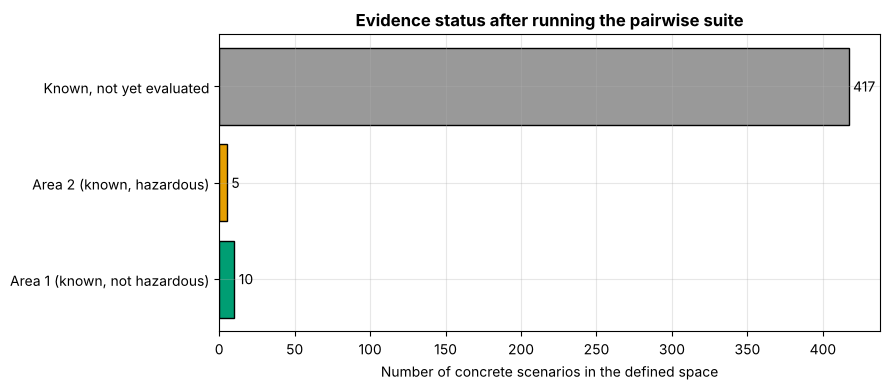

Text summary: Area 1 (known, not hazardous): 10; Area 2 (known, hazardous): 5; Known, not yet evaluated: 417 — Area 3/4 scenarios lie outside the parameterised space and are not represented here.


In [8]:
def classify_scenario(sc, test_results):
    """Place a concrete scenario of the defined space into an ISO 21448 area, based on evaluation evidence.

    test_results: dict mapping scenario key -> 'pass' | 'fail'.
    """
    key = tuple(sorted(sc.items()))
    outcome = test_results.get(key)
    if outcome == 'pass':
        return 'Area 1 (known, not hazardous)'
    if outcome == 'fail':
        return 'Area 2 (known, hazardous)'
    return 'Known, not yet evaluated'

test_results = {tuple(sorted(sc.items())): ('fail' if evaluate(sc)['hazardous'] else 'pass') for sc in pairwise_suite}
uni_df['status'] = [classify_scenario(sc, test_results) for sc in universe]
status_counts = uni_df['status'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
order = ['Area 1 (known, not hazardous)', 'Area 2 (known, hazardous)', 'Known, not yet evaluated']
colors = [OI['green'], OI['orange'], OI['grey']]
vals = [status_counts.get(o, 0) for o in order]
ax.barh(order, vals, color=colors, edgecolor='black')
for i, v in enumerate(vals):
    ax.text(v + 3, i, str(v), va='center')
ax.set_xlabel('Number of concrete scenarios in the defined space')
ax.set_title('Evidence status after running the pairwise suite', fontweight='bold')
plt.tight_layout(); plt.show()

print("Text summary:", "; ".join(f"{o}: {v}" for o, v in zip(order, vals)),
      "— Area 3/4 scenarios lie outside the parameterised space and are not represented here.")

**Coverage is not risk.** 100 % pairwise coverage says the *chosen* discretisation was explored at *pairwise*
depth. It does not say that the discretisation is fine enough (what happens at 45 km/h?), that the parameters are the
right ones (umbrella?), or how often each scenario occurs. A residual-risk argument therefore combines (i) coverage of
a well-justified scenario space, (ii) search for hazardous regions, and (iii) exposure-weighted statistical evidence —
see [Notebook 04](04_simulation_based_validation.ipynb).

## 7. Executable scenarios: ASAM OpenSCENARIO and tools

- **ASAM OpenSCENARIO XML** (current version 1.4.0, May 2026, as of October 2026; https://www.asam.net/standards/detail/openscenario-xml/)
  describes the dynamic content of a scenario — actors, manoeuvres, triggers — with **parameter declarations**; road
  networks are described in **ASAM OpenDRIVE**. **ASAM OpenSCENARIO DSL** is a domain-specific language for more
  abstract, logical scenarios.
- **esmini** is an open-source player for OpenSCENARIO XML; **CARLA** (with ScenarioRunner) also executes OpenSCENARIO.
- **ASAM OpenODD 1.0.0** (April 2025) describes ODDs in machine-readable form.

The cell below writes our pairwise test set as an OpenSCENARIO-style parameter value set. It is **schematic** —
it shows the idea (one logical scenario file + a list of concrete parameter assignments) and has not been validated
against the ASAM XML schema. No simulator is needed to run this notebook.

In [9]:
def to_parameter_sets(suite, max_sets=3):
    lines = ['<ParameterValueDistribution>',
             '  <ScenarioFile filepath="pedestrian_crossing_logical.xosc"/>',
             '  <Deterministic>',
             '    <DeterministicMultiParameterDistribution>',
             '      <ValueSetDistribution>']
    for sc in suite[:max_sets]:
        lines.append('        <ParameterValueSet>')
        for k, v in sc.items():
            lines.append(f'          <ParameterAssignment parameterRef="{k}" value="{v}"/>')
        lines.append('        </ParameterValueSet>')
    lines += ['        <!-- ... remaining concrete scenarios ... -->',
              '      </ValueSetDistribution>',
              '    </DeterministicMultiParameterDistribution>',
              '  </Deterministic>',
              '</ParameterValueDistribution>']
    return '\n'.join(lines)

print(f"Schematic OpenSCENARIO-style parameter sets (first 3 of {len(pairwise_suite)}):\n")
print(to_parameter_sets(pairwise_suite))

Schematic OpenSCENARIO-style parameter sets (first 3 of 15):

<ParameterValueDistribution>
  <ScenarioFile filepath="pedestrian_crossing_logical.xosc"/>
  <Deterministic>
    <DeterministicMultiParameterDistribution>
      <ValueSetDistribution>
        <ParameterValueSet>
          <ParameterAssignment parameterRef="ego_speed_kmh" value="30"/>
          <ParameterAssignment parameterRef="illumination" value="day"/>
          <ParameterAssignment parameterRef="occlusion" value="none"/>
          <ParameterAssignment parameterRef="ped_motion" value="walk"/>
          <ParameterAssignment parameterRef="pedestrian" value="adult"/>
          <ParameterAssignment parameterRef="precipitation" value="none"/>
          <ParameterAssignment parameterRef="road_surface" value="dry"/>
        </ParameterValueSet>
        <ParameterValueSet>
          <ParameterAssignment parameterRef="ego_speed_kmh" value="30"/>
          <ParameterAssignment parameterRef="illumination" value="dusk"/>
          <P

## 8. Validation strategy: combining test environments

| Method | Purpose | Typical scale (indicative) |
|---|---|---|
| **Simulation** (MiL/SiL/HiL) | Broad exploration, rare and dangerous scenarios, parameter sweeps | 10⁶–10⁹ km equivalent or 10⁴–10⁷ concrete runs |
| **Proving ground** | Physical sensors and vehicle in controlled scenarios; correlation of simulation | 10²–10⁴ scenario runs |
| **Public road / field operational test** | Real exposure, discovery of the unexpected | 10⁵–10⁷ km |
| **Analysis** (HARA, STPA, FMEA, formal methods) | Identification of hazards, insufficiencies and triggering conditions | Spans all of the above |

SOTIF validation aims to show that the residual risk from **known (Area 2)** and **unknown (Area 3)** hazardous
scenarios meets the acceptance criteria.

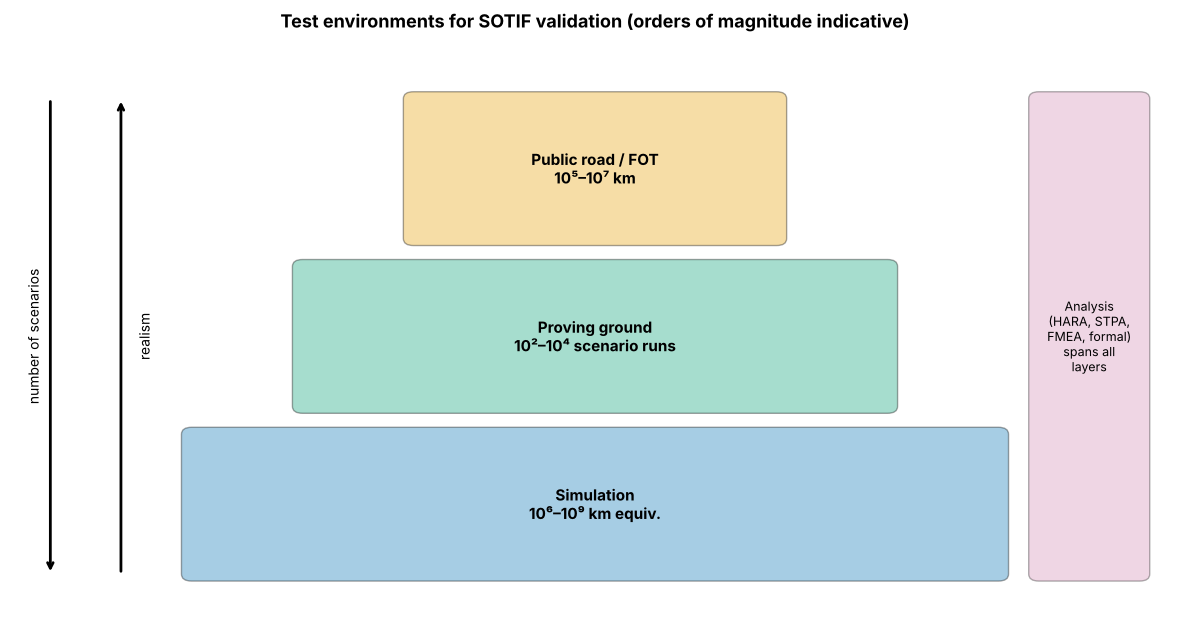

In [10]:
def visualize_validation_layers():
    """Test environments (pyramid) with analysis as a cross-cutting activity."""
    fig, ax = plt.subplots(figsize=(12, 6.5))
    layers = [('Simulation\n10⁶–10⁹ km equiv.', 0.80, OI['blue']),
              ('Proving ground\n10²–10⁴ scenario runs', 0.58, OI['green']),
              ('Public road / FOT\n10⁵–10⁷ km', 0.36, OI['orange'])]
    y = 0.08
    for label, width, col in layers:
        ax.add_patch(FancyBboxPatch((0.5 - width / 2, y), width, 0.2, boxstyle='round,pad=0.01',
                                    facecolor=col, alpha=0.35, edgecolor='black'))
        ax.text(0.5, y + 0.1, label, ha='center', va='center', fontsize=11, fontweight='bold')
        y += 0.24
    ax.add_patch(FancyBboxPatch((0.94, 0.08), 0.1, 0.68, boxstyle='round,pad=0.01',
                                facecolor=OI['purple'], alpha=0.3, edgecolor='black'))
    ax.text(0.99, 0.42, 'Analysis\n(HARA, STPA,\nFMEA, formal)\nspans all\nlayers', ha='center', va='center', fontsize=9)
    ax.annotate('', xy=(-0.04, 0.08), xytext=(-0.04, 0.76), arrowprops=dict(arrowstyle='->', lw=2))
    ax.text(-0.065, 0.42, 'number of scenarios', rotation=90, va='center', fontsize=10)
    ax.annotate('', xy=(0.03, 0.76), xytext=(0.03, 0.08), arrowprops=dict(arrowstyle='->', lw=2))
    ax.text(0.045, 0.42, 'realism', rotation=90, va='center', fontsize=10)
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(0, 0.85); ax.axis('off')
    ax.set_title('Test environments for SOTIF validation (orders of magnitude indicative)', fontsize=13,
                 fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_validation_layers()

## 9. Exercise: Lane Keeping Assist (LKA)

1. List at least five triggering conditions for an LKA, grouped by 6-layer model layer.
2. List the functional insufficiencies they activate; mark each as *specification* or *performance*.
3. Define a logical scenario (4–6 discretised parameters, at least one physical constraint).
4. Build a pairwise test set with `greedy_pairwise` and report 2- and 3-wise coverage.
5. Which hazardous scenarios could lie *outside* your parameterisation (Area 3 candidates)?

The starter code runs as it is; fill in the lists and domains.

In [11]:
# Exercise starter: Lane Keeping Assist
lka_triggering_conditions = {
    # 'L1 Road network': ['Faded lane markings', ...],
    # 'L5 Environment': ['Low sun on wet road', ...],
}
lka_insufficiencies = [
    # {'FI-ID': 'FI-L1', 'type': 'Performance', 'description': 'Lane detector misses low-contrast markings',
    #  'activated_by': ['Faded lane markings']},
]
lka_domains = {
    # 'curve_radius_m': [250, 500, 1000],
    # 'marking_quality': ['good', 'faded', 'missing'],
    # 'illumination': ['day', 'low_sun', 'night'],
    # 'road_surface': ['dry', 'wet'],
}

n_tc = sum(len(v) for v in lka_triggering_conditions.values())
print(f"Triggering conditions: {n_tc}; functional insufficiencies: {len(lka_insufficiencies)}")
if len(lka_domains) >= 2:
    lka_universe = full_factorial(lka_domains)
    lka_suite = greedy_pairwise(lka_universe, lka_domains)
    print(f"Pairwise suite: {len(lka_suite)} of {len(lka_universe)} scenarios; "
          f"3-wise coverage {nwise_coverage(lka_domains, lka_suite, min(3, len(lka_domains)))['coverage']:.0%}")
else:
    print("Define at least two parameters in lka_domains to build a pairwise suite.")

Triggering conditions: 0; functional insufficiencies: 0
Define at least two parameters in lka_domains to build a pairwise suite.


## Key takeaways

- A triggering-condition catalogue describes **the world**; structure it with the **6-layer model** and keep sensor
  exposure and driver misuse as separate groups. E/E faults and attacks belong to other standards.
- Functional insufficiencies are **specification** or **performance** insufficiencies of the system; training-data
  coverage gaps are performance insufficiencies.
- Scenarios are described at **functional, logical and concrete** level; the **ODD** (ISO 34503: scenery,
  environmental conditions, dynamic elements) bounds where the function may operate.
- **ISO 34502** frames scenario-based evaluation; **ASAM OpenSCENARIO/OpenDRIVE/OpenODD** make scenarios and ODDs executable.
- **n-wise coverage** of a discretised space is measurable and efficient to achieve, but it is not a measure of
  residual risk; higher-order interactions and Area 3 lie beyond it.

## Self-assessment

1. What is a scenario in the context of SOTIF, and how does it differ from an ODD?
2. Describe the three levels of scenario abstraction (functional, logical, concrete).
3. Is "out-of-distribution input" a triggering condition? Explain.
4. How can combinatorial testing reduce the number of scenarios to evaluate, and what can it miss?
5. Why can a scenario that has not been tested not be placed in Area 3 by a script?
6. Why is it impossible to test all possible driving scenarios exhaustively?

<details>
<summary>Answers</summary>

1. A scenario is a temporal sequence of scenes with the actions and events of the participants. The ODD describes the
   operating conditions under which the function is designed to work; scenarios happen inside, outside or across it.
2. Functional: linguistic description; logical: parameters with ranges or distributions; concrete: one fixed value
   per parameter, executable.
3. No. It describes a gap in the system's training-data coverage, i.e. a performance insufficiency. The triggering
   condition is the scenario condition (e.g. a wheelchair user) that the gap makes the system unable to handle.
4. n-wise test sets cover every combination of values of any n parameters with far fewer tests than the full
   factorial (here a handful instead of hundreds). They can miss failures that need more than n interacting
   conditions, values between grid points, and parameters that were never modelled.
5. Areas 3 and 4 are *unknown* scenarios — not part of anyone's list. A scenario in the defined space is known; if not
   yet evaluated it is "known, not yet evaluated", not Area 3.
6. The parameter space is continuous and high-dimensional, and the set of relevant parameters itself is open; even a
   coarse discretisation explodes combinatorially, and real-world exposure to rare combinations is tiny.
</details>

## References

- ISO 21448:2022 *Road vehicles — Safety of the intended functionality*.
- ISO 34502:2022 *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation framework*.
- ISO 34503:2023 *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*.
- SAE J3016 (2021) *Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles*.
- Menzel, T., Bagschik, G., Maurer, M. (2018). Scenarios for Development, Test and Validation of Automated Vehicles. *IEEE IV 2018*, 1821–1827. https://doi.org/10.1109/IVS.2018.8500406
- Scholtes, M., Westhofen, L., Turner, L. R., et al. (2021). 6-Layer Model for a Structured Description and Categorization of Urban Traffic and Environment. *IEEE Access* 9, 59131–59147. https://doi.org/10.1109/ACCESS.2021.3072739
- Riedmaier, S., Ponn, T., Ludwig, D., Schick, B., Diermeyer, F. (2020). Survey on Scenario-Based Safety Assessment of Automated Vehicles. *IEEE Access* 8, 87456–87477. https://doi.org/10.1109/ACCESS.2020.2993730
- Hou, Z., Liu, D., Yang, Y., Liu, H. (2024). Assessing Unknown Hazards for SOTIF Based on Twin Scenarios Empowered Autonomous Driving. *IEEE Internet of Things Journal* 11, 32631–32644. https://doi.org/10.1109/JIOT.2024.3424550 — an example of generating variations of known scenarios to search for unknown hazards.
- Patel, M., Jung, R., Khatun, M. (2025). A Systematic Literature Review on Safety of the Intended Functionality for Automated Driving Systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
- ASAM OpenSCENARIO XML: https://www.asam.net/standards/detail/openscenario-xml/ · ASAM OpenODD: https://www.asam.net/standards/detail/openodd/
- NIST Combinatorial Testing (ACTS): https://csrc.nist.gov/projects/automated-combinatorial-testing-for-software

---
**Navigation:** ← [prev: SOTIF fundamentals](01_sotif_fundamentals.ipynb) · [Module index](README.md) · [next: OOD monitoring as a safety measure](03_ood_monitoring_as_safety_measure.ipynb) →